# Budget forecaster: predicting next month's spending by category
**Stephanie Kim** · [Project page and live tool](https://stephaniekim62-cpu.github.io/projects/budget.html)

**Question:** can a simple, explainable model forecast monthly spending well enough to set a realistic budget, and which categories are likely to go over?

**Data:** `sample_transactions.csv` is a **fictional** student's spending from Sep 2023 to Oct 2026 (1,000 transactions), generated for this demo with realistic patterns: rent, semester vs. summer months, December flights home. To use your own data, upload a CSV with `date, category, amount` columns and change `DATA_URL`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.filterwarnings("ignore")
DATA_URL = "https://raw.githubusercontent.com/stephaniekim62-cpu/stephaniekim62-cpu.github.io/main/notebooks/sample_transactions.csv"
try:
    tx = pd.read_csv(DATA_URL, parse_dates=["date"])
except Exception:
    tx = pd.read_csv("sample_transactions.csv", parse_dates=["date"])   # if you uploaded the file to Colab
tx.head()

,date,category,amount,description
0,2023-09-01,Rent,1104.00,Apartment rent
1,2023-09-01,Entertainment,55.65,Events / movies
2,2023-09-02,Transport,38.16,Rideshare / transit
3,2023-09-05,Utilities & phone,95.89,"Electric, internet, phone"
4,2023-09-07,Shopping,20.25,Clothes / online order


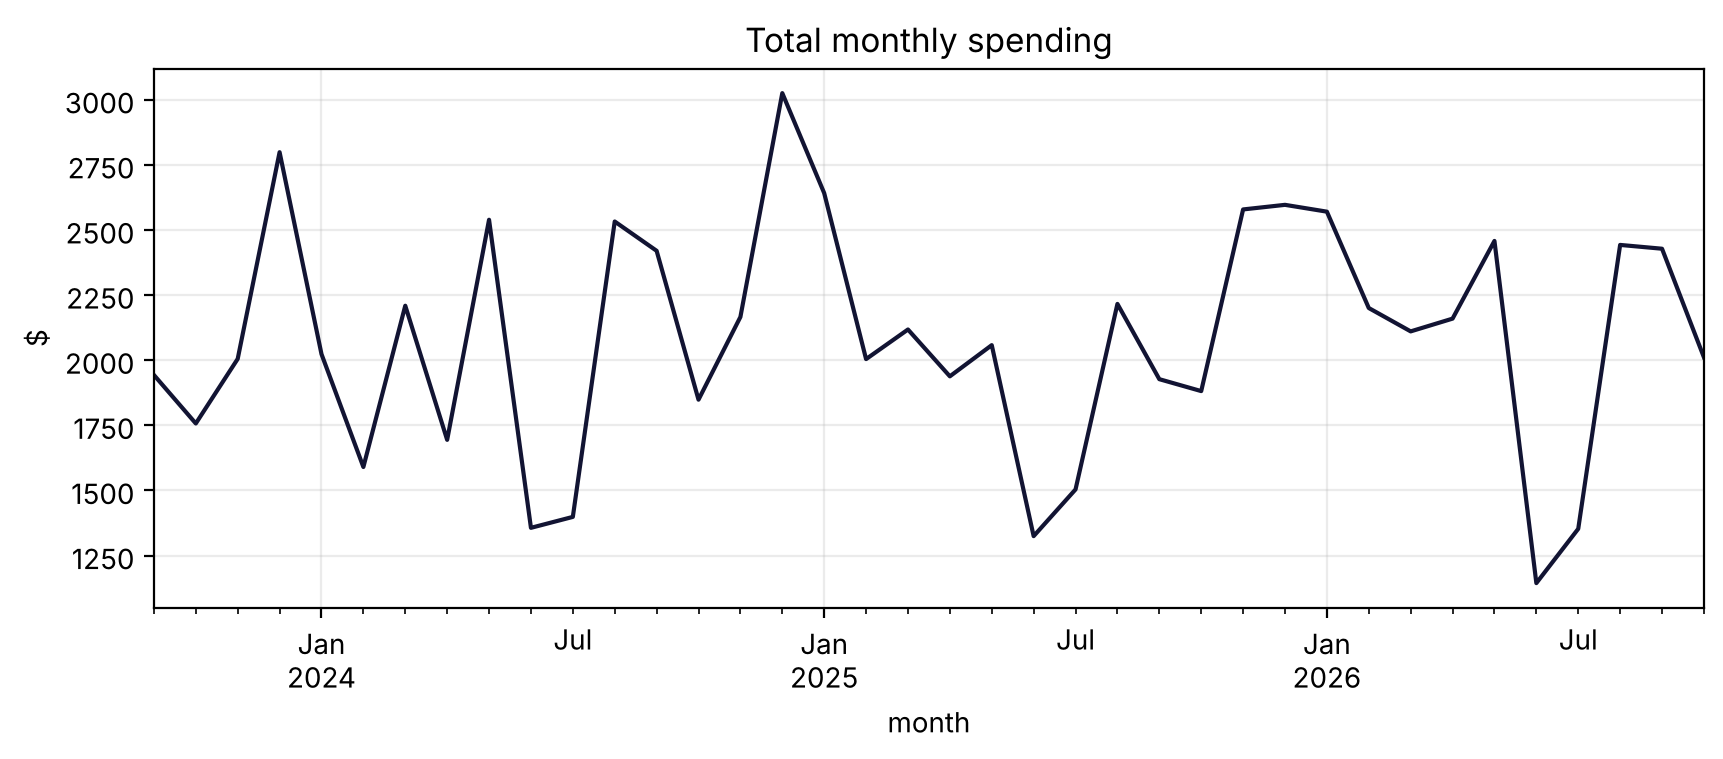

category,Books & school,Dining out,Entertainment,Groceries,Rent,Shopping,Subscriptions,Transport,Travel,Utilities & phone
month,,,,,,,,,,
2026-08,244.0,36.0,57.0,213.0,1196.0,0.0,34.0,55.0,486.0,123.0
2026-09,0.0,306.0,114.0,138.0,1196.0,495.0,34.0,63.0,0.0,83.0
2026-10,0.0,77.0,40.0,341.0,1196.0,154.0,34.0,55.0,0.0,115.0


In [2]:
monthly = (tx.assign(month=tx.date.dt.to_period("M"))
             .pivot_table(index="month", columns="category", values="amount", aggfunc="sum", fill_value=0))
total = monthly.sum(axis=1)
ax = total.plot(figsize=(10, 3.5), color="#121433", title="Total monthly spending"); ax.set_ylabel("$"); ax.grid(alpha=.25); plt.show()
monthly.tail(3).round(0)

## 1. Current inflation from the Bureau of Labor Statistics

In [3]:
cpi = pd.read_csv("https://raw.githubusercontent.com/datasets/cpi-us/main/data/cpiai.csv", parse_dates=["Date"]).set_index("Date").Index
inflation = cpi.iloc[-1] / cpi.iloc[-13] - 1
print(f"CPI inflation, year to {cpi.index[-1]:%b %Y}: {inflation:.1%}")

CPI inflation, year to Sep 2026: 4.0%


## 2. The forecasting method: seasonal average
1. **Base level** = average of the last 12 months.
2. **Seasonal adjustment** = for each calendar month, the average gap between that month and its trailing 12-month average.
3. **Forecast** = base level grown by inflation + seasonal adjustment (never below zero).

In [4]:
def seasonal_average(y, horizon, infl=0.0):
    y = np.asarray(y, float); n = len(y)
    base = y[-12:].mean() if n >= 12 else y.mean()
    gaps = {}
    for t in range(12, n):
        gaps.setdefault(t % 12, []).append(y[t] - y[t-12:t].mean())
    return np.array([max(0, base * (1 + infl) ** (k / 12) + np.mean(gaps.get((n - 1 + k) % 12, [0])))
                     for k in range(1, horizon + 1)])

## 3. Backtest: how wrong would each method have been?
For each of the last 14 months, forecast it using only the data before it, then measure the percentage error.

In [5]:
y = total.values
methods = {
    "Last month (naive)": lambda h: h[-1],
    "3-month average": lambda h: h[-3:].mean(),
    "12-month average": lambda h: h[-12:].mean(),
    "Seasonal average (mine)": lambda h: seasonal_average(h, 1)[0],
    "Holt-Winters (statsmodels)": lambda h: ExponentialSmoothing(h, seasonal="add", seasonal_periods=12,
                                                                 initialization_method="estimated").fit().forecast(1)[0],
}
errors = {name: np.mean([abs(f(y[:t]) - y[t]) / y[t] for t in range(24, len(y))]) for name, f in methods.items()}
pd.Series(errors, name="Mean absolute % error").sort_values().to_frame().style.format("{:.1%}")

,Mean absolute % error
Holt-Winters (statsmodels),10.8%
Seasonal average (mine),11.5%
Last month (naive),19.8%
12-month average,20.0%
3-month average,22.8%


My method cuts the naive error by about 40% and lands within a point of Holt-Winters, while staying simple enough to explain to a client in a sentence.

## 4. Six-month forecast with an 80% range

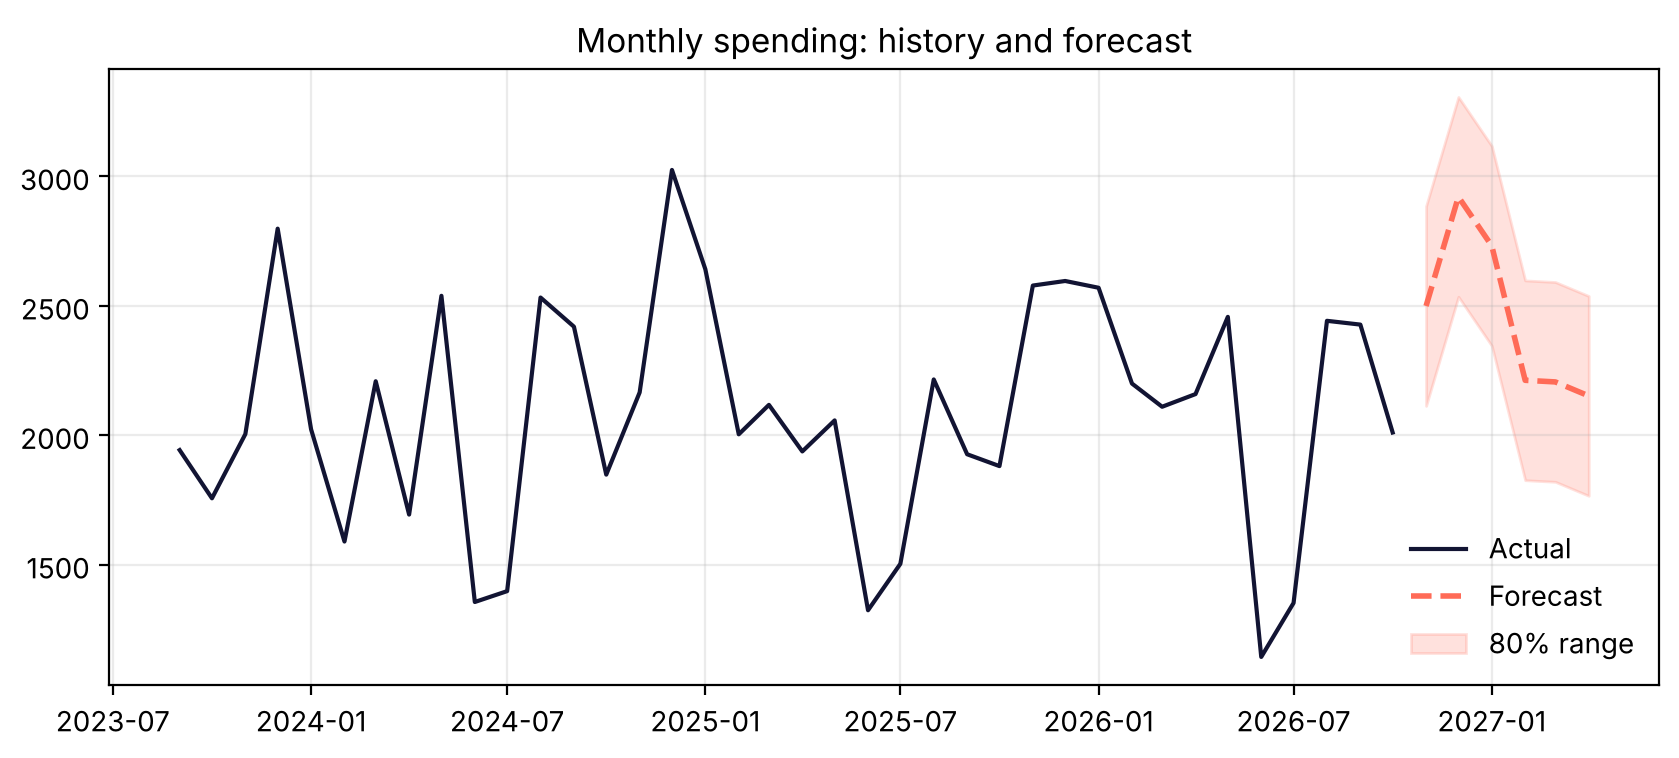

,Books & school,Dining out,Entertainment,Groceries,Rent,Shopping,Subscriptions,Transport,Travel,Utilities & phone,Total
2026-11,2.0,221.0,129.0,320.0,1230.0,395.0,36.0,65.0,1.0,101.0,2500.0
2026-12,2.0,302.0,106.0,197.0,1230.0,177.0,36.0,50.0,736.0,86.0,2922.0
2027-01,259.0,251.0,61.0,350.0,1229.0,368.0,36.0,63.0,5.0,110.0,2732.0
2027-02,1.0,323.0,43.0,200.0,1229.0,213.0,35.0,45.0,5.0,118.0,2212.0
2027-03,1.0,145.0,93.0,391.0,1229.0,167.0,35.0,48.0,6.0,93.0,2208.0
2027-04,1.0,339.0,35.0,298.0,1229.0,96.0,35.0,17.0,6.0,96.0,2152.0


In [6]:
fc = pd.DataFrame({c: seasonal_average(monthly[c], 6, inflation) for c in monthly.columns},
                  index=pd.period_range(monthly.index[-1] + 1, periods=6, freq="M"))
resid = np.std([seasonal_average(y[:t], 1)[0] - y[t] for t in range(24, len(y))])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(total.index.to_timestamp(), total.values, color="#121433", label="Actual")
ft = fc.sum(axis=1); x = ft.index.to_timestamp()
ax.plot(x, ft.values, "--", color="#ff6b57", lw=2, label="Forecast")
ax.fill_between(x, ft - 1.28 * resid, ft + 1.28 * resid, color="#ff6b57", alpha=.2, label="80% range")
ax.legend(frameon=False); ax.grid(alpha=.25); ax.set_title("Monthly spending: history and forecast"); plt.show()
fc.round(0).assign(Total=lambda d: d.sum(axis=1))

## 5. Which categories will probably go over budget?

In [7]:
from scipy.stats import norm
rows = []
for c in monthly.columns:
    s = monthly[c].values
    err = np.std([seasonal_average(s[:t], 1)[0] - s[t] for t in range(24, len(s))]) or 1
    med = np.median(s[-12:])
    budget = np.ceil((med if med > 0 else s[-12:].mean()) * 1.05 / 10) * 10
    f = fc[c].iloc[0]
    rows.append({"Category": c, "Forecast": f, "Budget": budget, "Chance over budget": 1 - norm.cdf((budget - f) / err)})
pd.DataFrame(rows).sort_values("Chance over budget", ascending=False).style.format(
    {"Forecast": "${:,.0f}", "Budget": "${:,.0f}", "Chance over budget": "{:.0%}"})

,Category,Forecast,Budget,Chance over budget
5,Shopping,$395,$190,95%
2,Entertainment,$129,$70,82%
3,Groceries,$320,$210,72%
7,Transport,$65,$60,56%
9,Utilities & phone,$101,$100,54%
1,Dining out,$221,$220,50%
6,Subscriptions,$36,$40,12%
8,Travel,$1,$140,4%
4,Rent,"$1,230","$1,260",4%
0,Books & school,$2,$50,1%


## Takeaways
1. A transparent seasonal average forecasts monthly spending with about **12% average error**, about 40% less than "same as last month."
2. **Seasonality matters more than trend** for a student budget: December travel, summers away and back-to-school shopping.
3. Budgets set at a "typical month" will predictably fail in seasonal months. Shopping in November is the clearest case. Budget by calendar month instead.

## Limitations
- Sample data is synthetic; real bank exports are messier, with refunds, transfers and split transactions.
- One-off purchases can't be forecast. The 80% range assumes errors look like past errors.
- Only about 3 years of history, so each month's seasonal adjustment rests on 2–3 observations.